In [1]:
import numpy as np
import pandas as pd
import os
import kagglehub
import pathlib
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, Dense, Dropout
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from pathlib import Path
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, BackupAndRestore
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from tensorflow.keras.models import load_model
import time

In [2]:
RAMDOM_STATE = 42
BATCH_SIZE= 32
EPOCHS = 10
image_size = (224, 224)

In [3]:
extensions_valides = (".jpg", ".jpeg", ".png", ".bmp")

labels_par_dossier = {
    "glioma": 0,
    "meningioma": 1,
    "notumor" : 2,
    "pituitary" : 3
}

In [6]:
# Download latest version
path = kagglehub.dataset_download("devana2004/dataset")

path = path +'/Data'
print("Path to dataset files:", path)


Path to dataset files: /kaggle/input/datasets/devana2004/dataset/Data


In [7]:

def check_data(path, extensions_valides, labels_par_dossier):
    num_skiped = 0
    num_corrompu = 0
    images= []
    labels = []
    try:
        data_dir = pathlib.Path(path)
        for folder in data_dir.iterdir():
            if folder.is_dir():
                for file in folder.iterdir():
                    if folder.name in labels_par_dossier.keys():
                        if not file.is_file():
                            continue

                        if file.is_file() and not file.name.lower().endswith(extensions_valides):
                            num_skiped +=1
                            continue

                        else:
                            image = cv2.imread(str(file))

                            if image is None:
                                num_corrompu +=1
                                continue
                            
                            else:
                                image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
                                images.append(image)
                                label = labels_par_dossier[folder.name]
                                labels.append(label)

        print('nombre de fichiers invlaid', num_skiped)
        print('nombre de fichiers corrompus', num_corrompu)
    except (FileNotFoundError):
        print("Erreur : Le fichier n'existe pas.")
    except Exception as e:
        # Capture toute autre erreur inattendue
        print(f"Erreur inattendue : {e}")
    return images, labels

images, labels = check_data(path, extensions_valides,  labels_par_dossier)

nombre de fichiers invlaid 0
nombre de fichiers corrompus 0


In [8]:
def preparing_data(image_size):
    images_resized =[]
    for image in images:
        resized = cv2.resize(image, image_size, interpolation=cv2.INTER_LINEAR)
        images_resized.append(resized)
    
    images_array_2d = np.array(images_resized)
    
    labeles_array_2d = np.array(labels)
    
    return images_array_2d, labeles_array_2d

images_array_2d, labeles_array_2d = preparing_data(image_size)
print(images_array_2d.shape, labeles_array_2d.shape)

(7023, 224, 224, 3) (7023,)


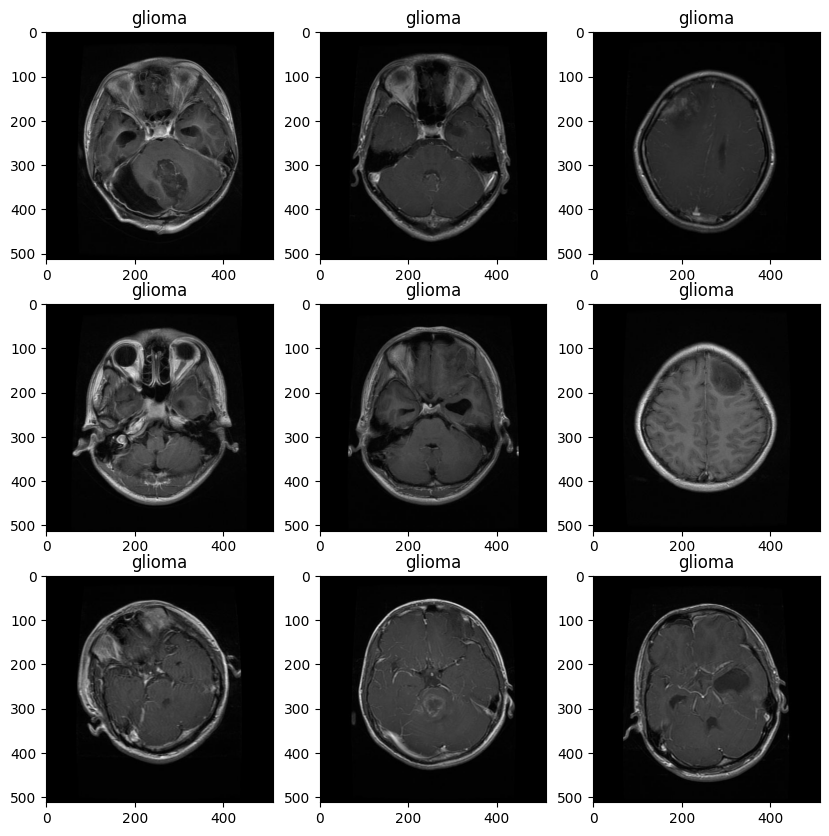

glioma : 1621 images
meningioma : 1645 images
notumor : 2000 images
pituitary : 1757 images


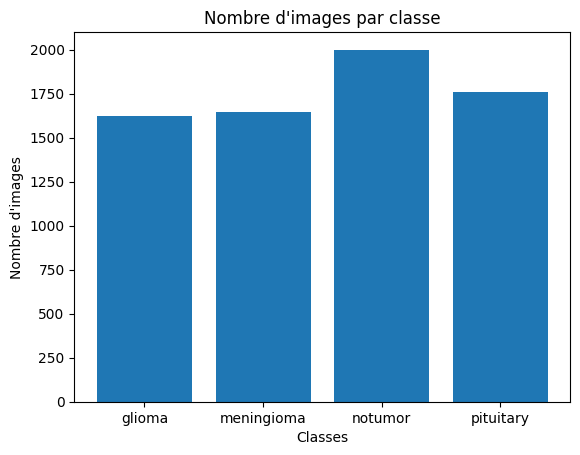

In [9]:
plt.figure(figsize=(10,10))
n_images = min(9, len(images))

for i in range(n_images):
    ax = plt.subplot(3,3,i+1)
    image_rgb = cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB)
    plt.imshow(image_rgb)
    nom_class = next((k for k, v in labels_par_dossier.items() if v == labels[i]), None)
    plt.title(nom_class)
plt.show()

effectifs = Counter(labels)

noms_classes = list(labels_par_dossier.keys())
nombres_images = [
    effectifs[labels_par_dossier[nom]]
    for nom in noms_classes
]

for nom, nombre in zip(noms_classes, nombres_images):
    print(f'{nom} : {nombre} images')

plt.bar(noms_classes, nombres_images)
plt.title("Nombre d'images par classe")
plt.xlabel('Classes')
plt.ylabel("Nombre d'images")
plt.show()

In [10]:
def spliting_data(X, y):
    X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RAMDOM_STATE)
    X_test, X_val, y_test, y_val = train_test_split(X_tmp, y_tmp, test_size=0.5,  stratify=y_tmp, random_state=RAMDOM_STATE)
    print(X_train.shape, X_test.shape, X_val.shape)
    print(y_train.shape, y_test.shape, y_val.shape)

    return  X_train, X_test, X_val, y_train, y_test, y_val
    
X_train, X_test, X_val, y_train, y_test, y_val = spliting_data(images_array_2d, labeles_array_2d)


def  normalisation(X, seuil):
    return X.astype('float32') / seuil


def prep(X, y, training=True):
    X = normalisation(X, 255.0)
    X_ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        X_ds = X_ds.shuffle(buffer_size=X_ds.cardinality())
        
    X_ds = X_ds.batch(batch_size=BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)

    return X_ds

Train_ds =  prep(X_train, y_train, training=True)
Test_ds = prep(X_test, y_test, training=False)
Val_ds = prep(X_val, y_val, training=False)
print(Train_ds, Test_ds, Val_ds)

(5618, 224, 224, 3) (702, 224, 224, 3) (703, 224, 224, 3)
(5618,) (702,) (703,)


I0000 00:00:1792533956.381274     143 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792533956.385059     143 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))> <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))> <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>


In [11]:
for image_batch, label_batch in Train_ds:
    print(image_batch.shape)
    print(label_batch.shape)
    break

(32, 224, 224, 3)
(32,)


In [12]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(
        height_factor=(-0.2, 0.2),
        width_factor=(-0.2, 0.2)
    ),
    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),
    layers.RandomZoom(0.1)
], name="data_augmentation")

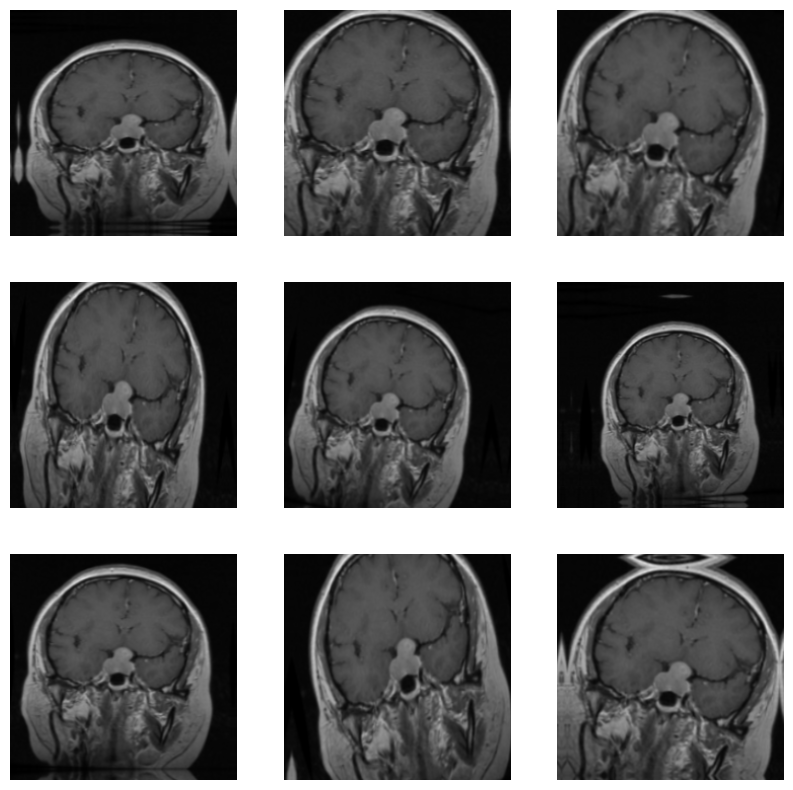

In [28]:
for image, _ in Train_ds.take(1):
      plt.figure(figsize=(10,10))
      first_image = image[0]
      for i in range(9):
            ax = plt.subplot(3, 3, i+1)
            augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
            plt.imshow(augmented_image[0])
            plt.axis('off')

In [29]:
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

In [30]:
IMG_SHAPE = image_size + (3,)
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE, include_top=False, weights='imagenet')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [31]:
image_batch, label_batch = next(iter(Train_ds))
feature_batch = base_model(image_batch)
print(feature_batch.shape)

(32, 7, 7, 1280)


In [32]:
base_model.trainable = False

In [33]:
base_model.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [34]:
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average = global_average_layer(feature_batch)
print(feature_batch_average.shape)

(32, 1280)


In [35]:
prediction_layer = tf.keras.layers.Dense(4)
prediction_batch = prediction_layer(feature_batch_average)
print(prediction_batch.shape)

(32, 4)


In [36]:
inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x  = global_average_layer(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)

In [37]:
base_learing_rate = 0.0001
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learing_rate),
            loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
      metrics=['accuracy'])

In [38]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [39]:
len(model.trainable_variables)

2

In [40]:
loss0, accuracy0 = model.evaluate(Val_ds)
print('initial loss {:.2f}'.format(loss0))
print('initial accuracy {:.2f}'.format(accuracy0))

22/22 ━━━━━━━━━━━━━━━━━━━━ 7s 77ms/step - accuracy: 0.2504 - loss: 1.7317
initial loss 1.73
initial accuracy 0.25


In [ ]:
# model = models.Sequential()
# model.add(layers.Input(shape=(224, 224, 3)))
# model.add(data_augmentation)
# model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)))
# model.add(layers.MaxPooling2D((2, 2)))
# model.add(layers.Conv2D(64, (3, 3), activation='relu'))
# model.add(layers.MaxPooling2D((2, 2)))
# model.add(layers.Conv2D(64, (3, 3), activation='relu'))
# model.add(layers.Flatten())
# model.add(layers.Dense(64, activation='relu'))
# model.add(layers.Dense(4))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 173056)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │    11,075,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,132,228 (42.47 MB)

 Trainable params: 11,132,228 (42.47 MB)

 Non-trainable params: 0 (0.00 B)

In [41]:
# Path("models").mkdir(parents=True, exist_ok=True)
Path("backup").mkdir(parents=True, exist_ok=True)

output_dir = Path("/kaggle/working/models")
output_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = output_dir / "bestt_model.keras"

In [42]:
# model.compile(optimizer='adam',
#               loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
#               metrics=['accuracy'])

checkpoint = ModelCheckpoint(
    filepath=str(checkpoint_path),
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)
callback = EarlyStopping(monitor='val_loss',patience=3, mode='min', restore_best_weights=True)
backup = BackupAndRestore(
    'backup/', save_freq="epoch", double_checkpoint=True, delete_checkpoint=False
)

In [43]:
debut = time.time()

history = model.fit(Train_ds, epochs=EPOCHS, 
                  validation_data=(Val_ds),  callbacks=[checkpoint, callback, backup])

fin = time.time()

duree = fin - debut

print(f"Durée de l'entraînement : {duree:.2f} secondes")
print(f"Durée en minutes : {duree / 60:.2f} minutes")

Epoch 1/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.2369 - loss: 1.5308
Epoch 1: val_accuracy improved from None to 0.28450, saving model to /kaggle/working/models/bestt_model.keras

Epoch 1: finished saving model to /kaggle/working/models/bestt_model.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 20s 82ms/step - accuracy: 0.2414 - loss: 1.4887 - val_accuracy: 0.2845 - val_loss: 1.3664
Epoch 2/10
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.2728 - loss: 1.4375
Epoch 2: val_accuracy improved from 0.28450 to 0.30583, saving model to /kaggle/working/models/bestt_model.keras

Epoch 2: finished saving model to /kaggle/working/models/bestt_model.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - accuracy: 0.2682 - loss: 1.4345 - val_accuracy: 0.3058 - val_loss: 1.3346
Epoch 3/10
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.2835 - loss: 1.4196
Epoch 3: val_accuracy did not improve from 0.30583
176/176 ━━━━━━━━━━━━━━━━━━━━ 12s 69ms/step - accuracy: 0.2839 - loss: 1.417

Text(0.5, 1.0, "Visualisation de la courbe d'apprentissage - Accuracy")

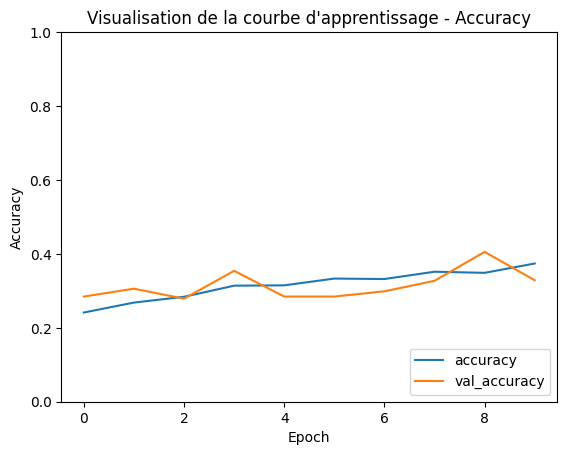

In [45]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')
plt.title("Visualisation de la courbe d'apprentissage - Accuracy")

In [46]:
Y = model.predict(Test_ds)
y_pred=np.argmax(Y, axis=1)

22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 121ms/step


22/22 - 1s - 57ms/step - accuracy: 0.4288 - loss: 1.2255


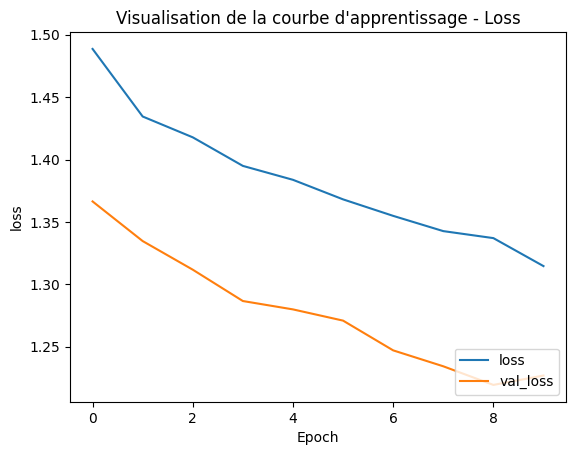

In [47]:
plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label = 'val_loss')
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.title("Visualisation de la courbe d'apprentissage - Loss")
plt.legend(loc='lower right')

test_loss, test_acc = model.evaluate(Test_ds, verbose=2)

In [48]:
y_true = np.concatenate([
    labels.numpy() for  images, labels in Test_ds
])

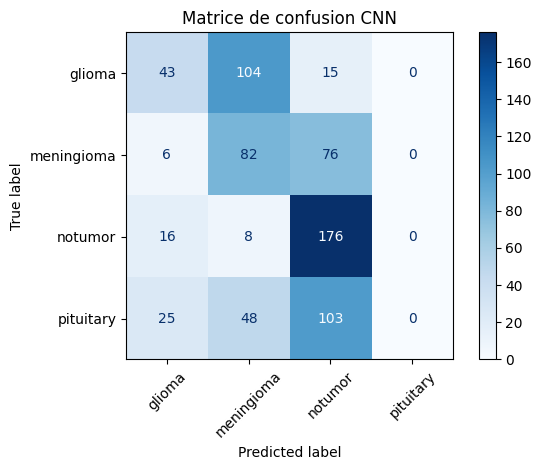

In [49]:
cm = confusion_matrix(y_true, y_pred)

effectifs = Counter(labels)

noms_classes = list(labels_par_dossier.keys())

cms = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=noms_classes)
cms.plot(cmap='Blues', xticks_rotation=45)
plt.title("Matrice de confusion CNN")
plt.tight_layout()
plt.show()

In [50]:
print(classification_report(y_true, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.48      0.27      0.34       162
           1       0.34      0.50      0.40       164
           2       0.48      0.88      0.62       200
           3       0.00      0.00      0.00       176

    accuracy                           0.43       702
   macro avg       0.32      0.41      0.34       702
weighted avg       0.32      0.43      0.35       702



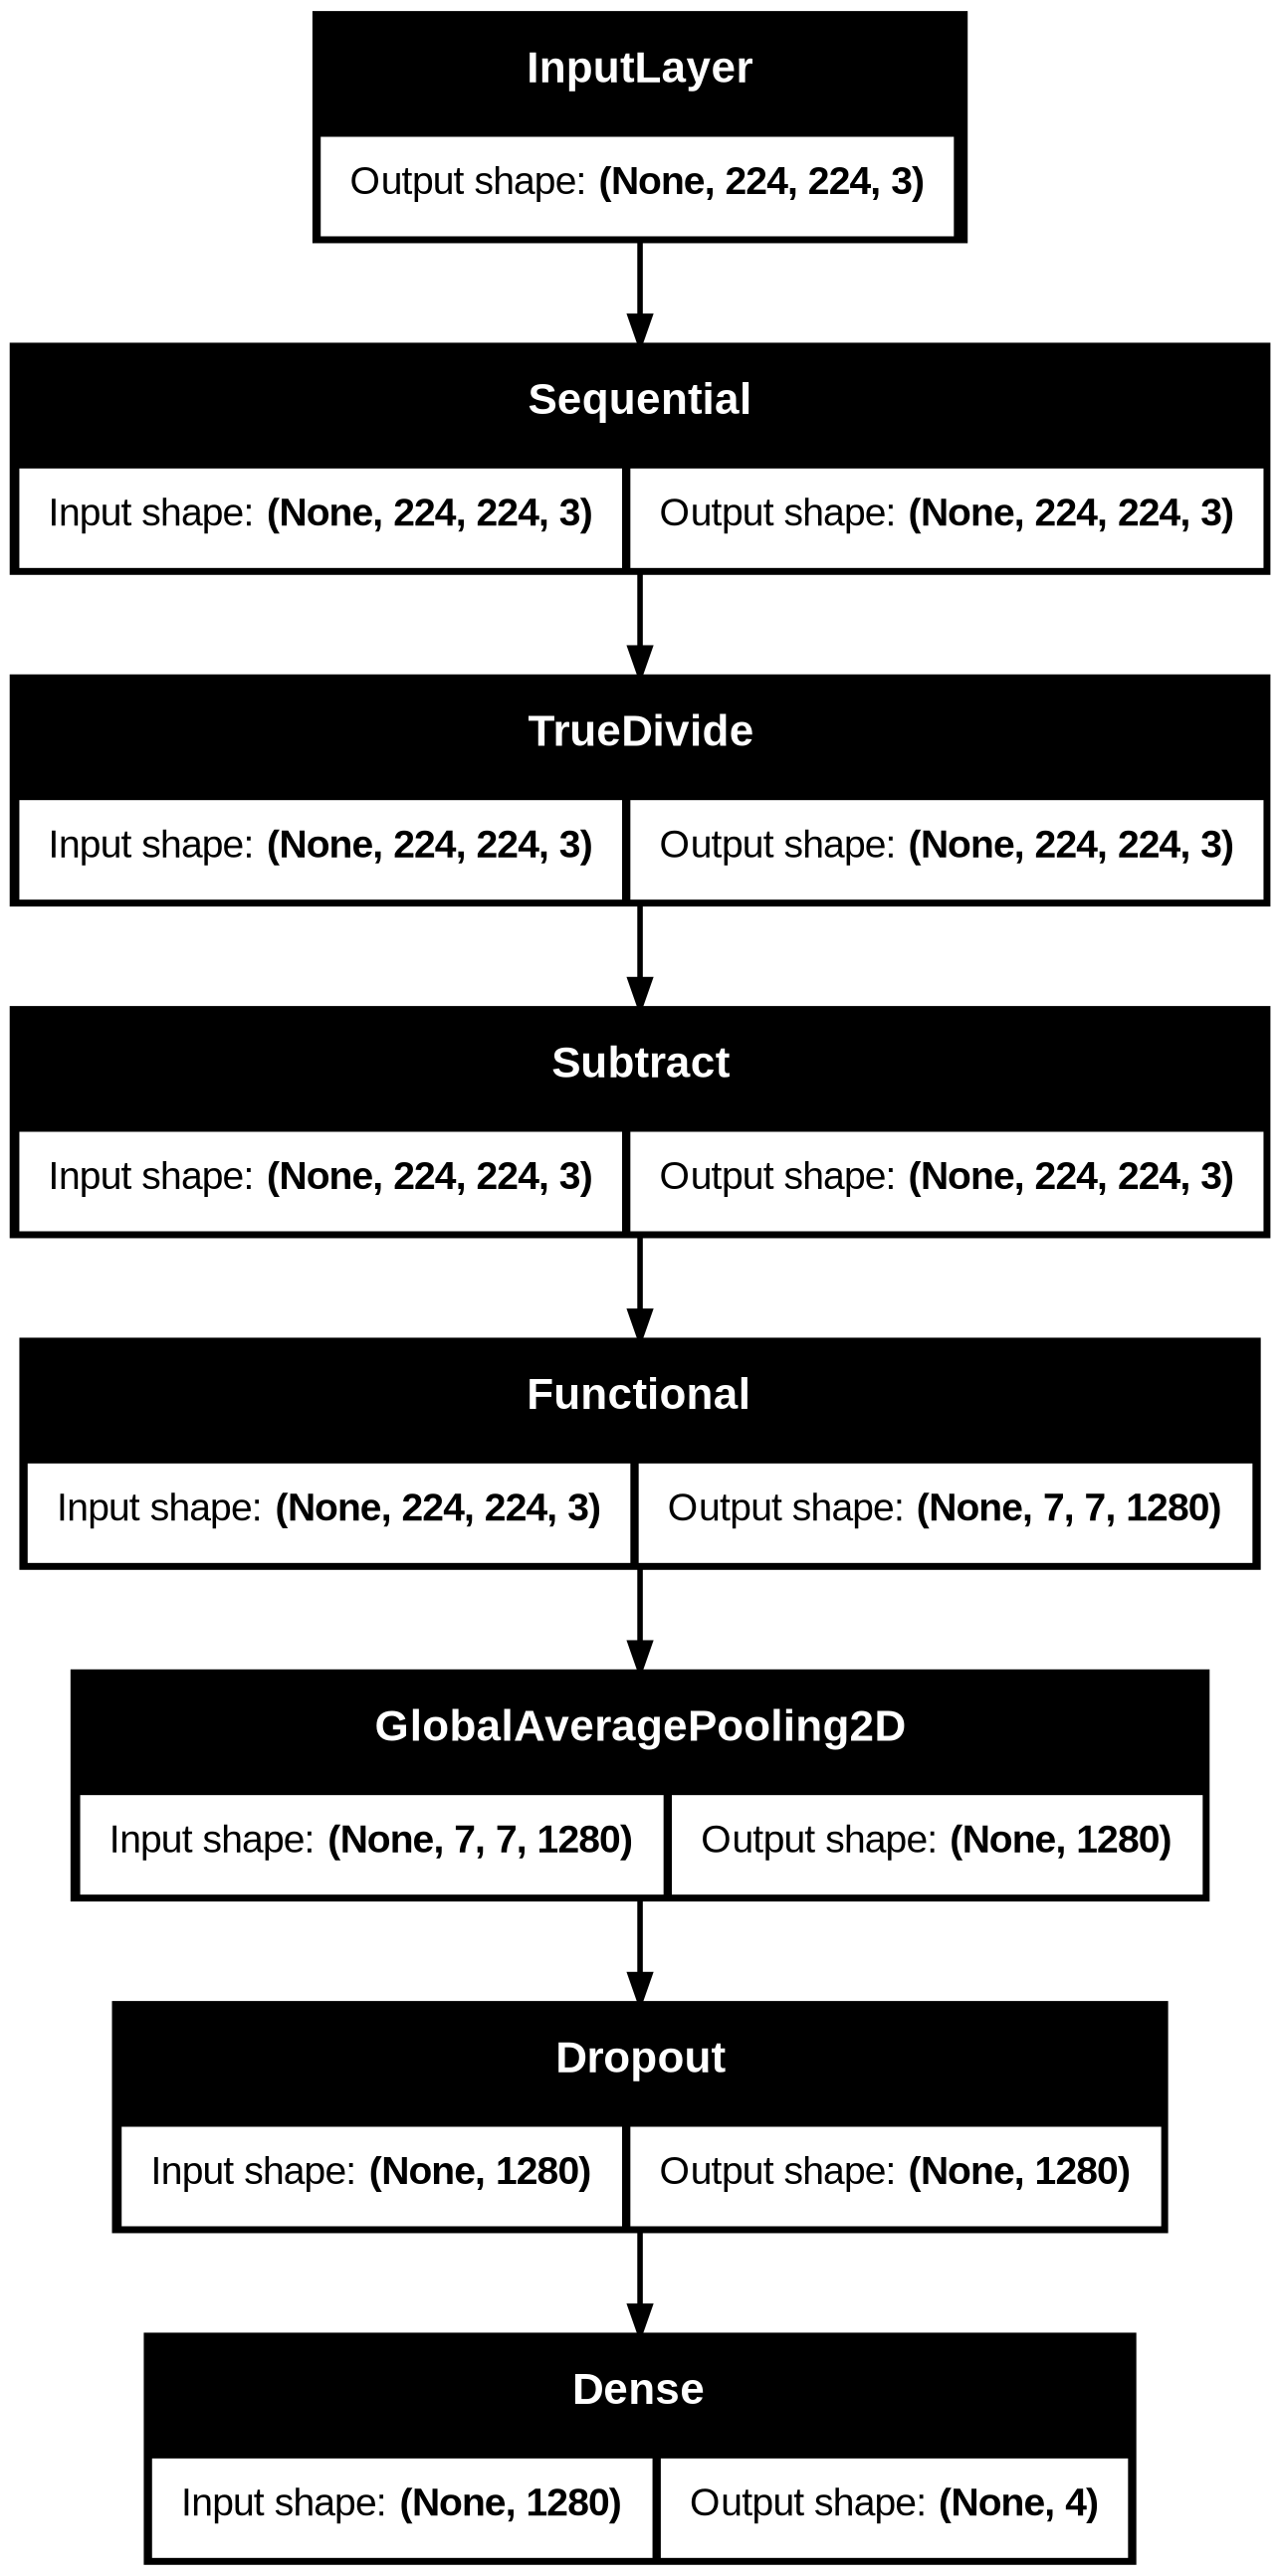

In [51]:
out_dir = Path("/kaggle/working/tmp")
out_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path1 = output_dir / "plot_model.png"
tf.keras.utils.plot_model(model, to_file=str(checkpoint_path1), show_shapes=True)

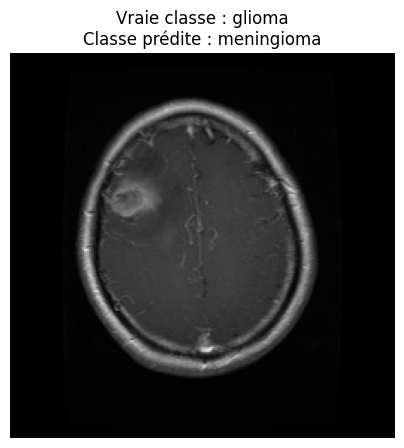

In [52]:
i = len(y_true) - 3

# Récupérer les images du dataset dans le même ordre
images_all = np.concatenate([
    images.numpy() for images, labels in Test_ds
])

class_names = ['glioma', 'meningioma', 'notumor', 'pituitary']

# Afficher l'image exacte
plt.figure(figsize=(5, 5))
plt.imshow(images_all[i])
plt.title(
    f"Vraie classe : {class_names[int(y_true[i])]}\n"
    f"Classe prédite : {class_names[int(y_pred[i])]}"
)
plt.axis("off")
plt.show()

In [53]:
best_model = load_model(checkpoint_path)
best_model.summary()
test_loss, test_accuracy = best_model.evaluate(Test_ds)

print("Test accuracy :", test_accuracy)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,273,358 (8.67 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 10,250 (40.04 KB)

22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - accuracy: 0.4288 - loss: 1.2255
Test accuracy : 0.4287749230861664


In [54]:
import json
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Les classes doivent respecter l'ordre utilisé pendant l'entraînement
class_names = [
    "Gliome",
    "Méningiome",
    "Aucune tumeur",
    "Tumeur hypophysaire"
]

# 1. Récupérer les vraies classes du jeu de test
y_true = np.concatenate([
    labels.numpy() for images, labels in Test_ds
])

# Gérer les labels one-hot, si nécessaire
if y_true.ndim > 1:
    y_true = np.argmax(y_true, axis=1)

# 2. Prédictions du modèle
y_prob = model.predict(Test_ds)
y_pred = np.argmax(y_prob, axis=1)

# 3. Métriques globales
metrics = {
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "precision": float(
        precision_score(y_true, y_pred, average="weighted", zero_division=0)
    ),
    "recall": float(
        recall_score(y_true, y_pred, average="weighted", zero_division=0)
    ),
    "f1_score": float(
        f1_score(y_true, y_pred, average="weighted", zero_division=0)
    ),

    # 4. Matrice de confusion
    "confusion_matrix": confusion_matrix(
        y_true, y_pred, labels=range(len(class_names))
    ).tolist(),

    "class_names": class_names,

    # 5. Rapport détaillé par classe
    "classification_report": classification_report(
        y_true,
        y_pred,
        labels=range(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
}

# 6. Courbes d'apprentissage enregistrées pendant model.fit()
if "history" in globals() and history is not None:
    metrics["learning_curves"] = {
        key: [float(value) for value in values]
        for key, values in history.history.items()
    }

# 7. Enregistrer le JSON dans le projet
output_path = Path("metrics_transfer.json")

with output_path.open("w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4, ensure_ascii=False)

print(f"Métriques sauvegardées dans : {output_path.resolve()}")

22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step
Métriques sauvegardées dans : /kaggle/working/metrics_transfer.json
